## Analysing snippets

In [11]:
import pandas as pd
from driver import clean_text, get_text_stats
import numpy as np
import re

results_navigation = pd.read_csv("Data/results_navigation.csv")
results_navigation["timestamp"] = pd.to_datetime(results_navigation["timestamp"])

results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: clean_text(x))
# results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: re.sub(
#     r'^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)\s+\d{1,2},\s+\d{4}\s*(?:\.\.\.)?\s*',
#     '',
#     x,
#     flags=re.IGNORECASE
# ))
results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: x.strip())
results_navigation["SERP_result"] = [str(title).strip()+snippet for title, snippet in zip(results_navigation["title"], results_navigation["snippet"])]

text_stat_results = get_text_stats(results_navigation, "SERP_result")

results_navigation["SERP_result_content_len"] = text_stat_results["content_len"]
results_navigation["SERP_result_mean_aoa"] = text_stat_results["mean_aoa"]
results_navigation["SERP_result_mean_conc"] = text_stat_results["mean_conc"]
results_navigation["SERP_result_gulpease_index"] = text_stat_results["gulpease_index"]
# results_navigation["snippet_fres"] = text_stat_results["fres"]

  0%|          | 0/930 [00:00<?, ?it/s]

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [14]:
results_navigation.to_csv("Data/results_navigation.csv", index=False, encoding='utf8')

In [15]:
results_navigation.loc[pd.isna(results_navigation["rank"])]

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index


## Analysing navigation

In [1]:
import pandas as pd

# nlp = spacy.load("it_core_news_sm")
navigation_quality = pd.read_csv("Data/navigation_quality.csv")
navigation_quality["last_relevant_timestamp"] = pd.to_datetime(navigation_quality["last_relevant_timestamp"])
navigation_quality["effective_nav"] = [int(nav_eff >= 0.8) for nav_eff in navigation_quality["nav_eff"]]

serp_df = pd.read_csv("Data/results_navigation.csv")

query_df = pd.read_csv("Data/query_df.csv")
query_df["timestamp"] = pd.to_datetime(query_df["timestamp"])

click_df = pd.read_csv("Data/clicked_results_df.csv")
click_df["timestamp"] = pd.to_datetime(click_df["timestamp"])

view_df = pd.read_csv("Data/viewed_results_df.csv")
view_df["timestamp"] = pd.to_datetime(view_df["timestamp"])

In [2]:
serp_df.head()

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://wwftravel.it/blog/viaggi/india-natura-...,"India naturalistica, 5 animali da non perdere ...","Oct 31, 2023 ... La fauna selvatica dell'India...",1,1,2,2026-05-19 14:51:27.687,"India naturalistica, 5 animali da non perdere ...",29,6.270000,7.875000,58.022989
1,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.terreincognitemagazine.it/natura-s...,"Natura selvaggia in India, tra tigri e leoni -...","Feb 17, 2017 ... O dei Giganti, vista la mole ...",2,1,0,2026-05-19 14:51:27.688,"Natura selvaggia in India, tra tigri e leoni -...",36,6.864000,5.666667,66.250000
2,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.storicang.it/a/civilta-dellindo-i-...,"La civiltà dell'Indo, i misteri di un popolo d...","Jun 5, 2023 ... Sono note cinque metropoli, tr...",3,0,0,2026-05-19 14:51:27.689,"La civiltà dell'Indo, i misteri di un popolo d...",29,NaN,NaN,65.363636
3,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/scuola/storia/chi-s...,"Chi sono gli Indiani d'America, i nativi ameri...","Jun 6, 2024 ... Chi sono, da dove vengono e qu...",4,0,0,2026-05-19 14:51:27.690,"Chi sono gli Indiani d'America, i nativi ameri...",31,NaN,NaN,61.536765
4,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/comportamento/feste...,Festa della mamma: come si festeggia nel resto...,Il dolce tipico per celebrare questo giorno è ...,5,0,0,2026-05-19 14:51:27.691,Festa della mamma: come si festeggia nel resto...,34,3.914286,7.200000,64.444015


In [3]:
(query_df["timestamp"].max() - query_df["timestamp"].min()).total_seconds()

17030.947

In [4]:
query_df["timestamp"].mean()

Timestamp('2026-05-19 13:09:04.049101824')

In [5]:
view_temp_df = view_df.loc[(view_df["serp_id"]=="serp10") & (view_df["viewType"]=="resultExposureEnded")]
view_temp_df["rank"].value_counts(), view_temp_df["rank"].value_counts().mean()

(rank
 1    2
 2    2
 3    2
 7    1
 6    1
 5    1
 4    1
 Name: count, dtype: int64,
 np.float64(1.4285714285714286))

In [6]:
import numpy as np

first_click_time = [] # time from query entry to first click
avg_SERP_dwell_time_before_click = [] # how much time is spent on the SERP before a click
# avg_snippet_dwell_time = [] # average time for which a snippet is viewed at a time 
rank_lowest_view = [] # rank of the lowest viewed result
avg_snippet_view_counts_before_click = [] # average number of times a user views a snippet before clicking
avg_snippet_dwell_time_before_scroll_before_click = [] # average time a user dwells on a snippet before scrolling prior to making a click

SERP_avg_aoa = []
SERP_avg_conc = []
SERP_avg_length = []
SERP_avg_gulpease_index = []

for serp_id in navigation_quality["serp_id"]:
    query_temp_df = query_df.loc[query_df["serp_id"] == serp_id]
    click_temp_df = click_df.loc[click_df["serp_id"] == serp_id]
    serp_temp_df = serp_df.loc[serp_df["serp_id"]==serp_id]
    view_temp_df = view_df.loc[(view_df["serp_id"]==serp_id) & (view_df["viewType"]=="resultExposureEnded")]

    first_click_time.append((click_temp_df["timestamp"].min() - query_temp_df["timestamp"].min()).total_seconds())
    rank_lowest_view.append(view_temp_df["rank"].max())

    time_before_click = []
    snippet_dwell_time_before_scroll = []
    avg_snippet_view_counts = []

    for _, click in click_temp_df.iterrows():
        views_before_click = view_temp_df.loc[view_temp_df["associated_click_timestamp"]==click["timestamp"]]
        time_before_click.append((click["timestamp"] - views_before_click["timestamp"].min()).total_seconds())
        snippet_dwell_time_before_scroll.append(np.mean(views_before_click["viewDurationInSeconds"]))
        avg_snippet_view_counts.append(views_before_click["rank"].value_counts().mean())

    avg_SERP_dwell_time_before_click.append(np.mean(time_before_click))
    avg_snippet_dwell_time_before_scroll_before_click.append(np.mean(snippet_dwell_time_before_scroll))
    avg_snippet_view_counts_before_click.append(np.mean(avg_snippet_view_counts))

    # if len(click_temp_df) <= 1:
    #     avg_dwell_time_before_click.append(0)
    # else:
    #     click_temp_df = click_df.loc[click_df["serp_id"] == serp_id]

    #     for i, clicks in click_temp_df[1:].iterrows():
    #         time_before_click.append((click_temp_df.iloc[i]["timestamp"]- click_temp_df.iloc[i-1]["timestamp"]).total_seconds())
    #     avg_dwell_time_before_click.append(np.mean(time_before_click))

    SERP_avg_aoa.append(pd.Series([aoa for aoa in serp_temp_df["SERP_result_mean_aoa"]]).mean())
    SERP_avg_conc.append(pd.Series([conc for conc in serp_temp_df["SERP_result_mean_conc"]]).mean())
    SERP_avg_gulpease_index.append(pd.Series([gulp_ind for gulp_ind in serp_temp_df["SERP_result_gulpease_index"]]).mean())
    SERP_avg_length.append(pd.Series([cont_len for cont_len in serp_temp_df["SERP_result_content_len"]]).mean())


navigation_quality["first_click_time"] = first_click_time
navigation_quality["avg_SERP_dwell_time_before_click"] = avg_SERP_dwell_time_before_click
navigation_quality["avg_snippet_dwell_time_before_scroll_before_click"] = avg_snippet_dwell_time_before_scroll_before_click
navigation_quality["avg_snippet_view_counts_before_click"] = avg_snippet_view_counts_before_click
navigation_quality["rank_lowest_view"] = rank_lowest_view

navigation_quality["SERP_avg_aoa"] = SERP_avg_aoa
navigation_quality["SERP_avg_conc"] = SERP_avg_conc
navigation_quality["SERP_avg_gulpease_index"] = SERP_avg_gulpease_index
navigation_quality["SERP_avg_length"] = SERP_avg_length

navigation_quality.to_csv("Data/navigation_quality.csv", index=False, encoding="utf8")

In [7]:
navigation_quality.head()

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,nav_eff,...,avg_time_between_clicks,rank_lowest_click,SERP_avg_aoa,SERP_avg_conc,SERP_avg_gulpease_index,SERP_avg_length,avg_SERP_dwell_time_before_click,avg_snippet_dwell_time_before_scroll_before_click,avg_snippet_view_counts_before_click,rank_lowest_view
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,2,1,0,2026-05-19 14:53:19.408,0.5,...,95.964,1,5.632918,6.431042,66.377603,31.200,NaN,NaN,NaN,10.0
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,serp2,1,0,0,2026-05-19 15:02:48.776,1.0,...,0.000,1,4.690000,6.150000,61.852665,30.000,NaN,NaN,NaN,1.0
2,1,g3t1,q3,Fiume sacro degli indiani,serp3,1,0,0,2026-05-19 15:08:58.405,1.0,...,0.000,2,4.974583,7.119792,55.810356,32.875,NaN,NaN,NaN,2.0
3,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,serp5,1,0,0,2026-05-19 14:52:53.759,1.0,...,0.000,1,5.786159,6.757083,69.356585,31.700,NaN,NaN,NaN,7.0
4,2,g3t2,q7,Qual è il nome del simbolo al centro della b...,serp7,1,0,0,2026-05-19 15:09:25.575,1.0,...,0.000,3,5.181111,6.633889,66.741933,32.000,NaN,NaN,NaN,3.0


## Visualisation

In [9]:
from driver import get_significance
import pandas as pd

navigation_quality = pd.read_csv("Data/navigation_quality.csv")
categories = ["first_click_time", "avg_SERP_dwell_time_before_click", "avg_snippet_dwell_time_before_scroll_before_click", "avg_snippet_view_counts_before_click", "rank_lowest_view", "SERP_avg_length", "SERP_avg_gulpease_index", "SERP_avg_conc", "SERP_avg_aoa"]

sig_test_results = get_significance(df=navigation_quality, performance_metric="nav_eff", threshold=0.8, stage="results_navigation", categories=categories)
sig_test_results.to_csv("Data/sig_test_results_navigation.csv", index=False, encoding="utf8")
sig_test_results

,search_stage,feature,ineffective_vs_effective_feature_mean_val_diff,pval,significant
0,results_navigation,first_click_time,3.838654,0.8922,False
1,results_navigation,avg_SERP_dwell_time_before_click,NaN,0.0002,True
2,results_navigation,avg_snippet_dwell_time_before_scroll_before_click,NaN,0.0002,True
3,results_navigation,avg_snippet_view_counts_before_click,NaN,0.0002,True
4,results_navigation,rank_lowest_view,2.088942,0.0616,False
5,results_navigation,SERP_avg_length,0.464848,0.2584,False
6,results_navigation,SERP_avg_gulpease_index,2.743612,0.0158,True
7,results_navigation,SERP_avg_conc,-0.390664,0.0108,True
8,results_navigation,SERP_avg_aoa,0.139751,0.1258,False


UnboundLocalError: local variable 'boxprops' referenced before assignment

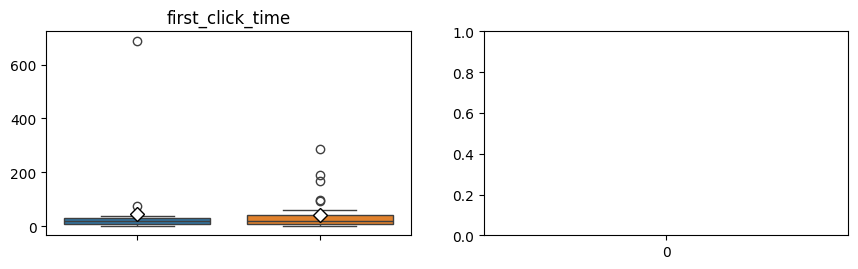

In [11]:
from driver import get_boxplots

get_boxplots(navigation_quality, "results_navigation", categories, group="effective_nav", artefact="navigation", n_cols=3, n_rows=3, stats_df=sig_test_results)

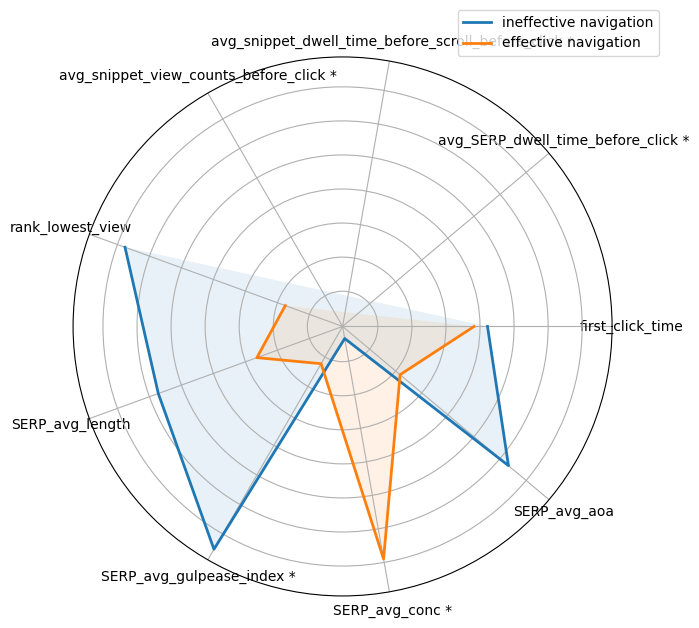

In [12]:
from driver import get_radar_plot

get_radar_plot(navigation_quality, "results_navigation", categories, group="effective_nav", artefact="navigation", normalized=True, stats_df=sig_test_results)